# Employee Performance Analysis - Model Training
In this notebook we train three models (Random Forest, Logistic Regression and Support Vector Machine) to predict the performance rating, and compare them.

In [1]:
import pandas as pd
import numpy as np

encoded_data = pd.read_csv('../../data/processed/encoded_data.csv')
encoded_data.shape

(1200, 27)

In [2]:
X = encoded_data.drop('PerformanceRating', axis=1)
y = encoded_data['PerformanceRating']

## Splitting the Data
We keep 80% of the employees for training and 20% for testing. The split keeps the same share of each rating in both parts, because the ratings are imbalanced.

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(2))
print(y_test.value_counts(normalize=True).round(2))

(960, 26) (240, 26)
PerformanceRating
3    0.73
2    0.16
4    0.11
Name: proportion, dtype: float64
PerformanceRating
3    0.73
2    0.16
4    0.11
Name: proportion, dtype: float64


## Scaling the Data
Logistic Regression and Support Vector Machine are sensitive to the size of the numbers, so we scale the values. Random Forest does not need scaling.

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Training the Models
We train Random Forest on the original values, and Logistic Regression and Support Vector Machine on the scaled values.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
print('Random Forest accuracy:', accuracy_score(y_test, rf_pred))

Random Forest accuracy: 0.9375


In [6]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)
print('Logistic Regression accuracy:', accuracy_score(y_test, lr_pred))

Logistic Regression accuracy: 0.825


In [7]:
from sklearn.svm import SVC

svm_model = SVC()
svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)
print('Support Vector Machine accuracy:', accuracy_score(y_test, svm_pred))

Support Vector Machine accuracy: 0.8333333333333334


In [8]:
results = pd.DataFrame({
    'Model': ['Random Forest', 'Logistic Regression', 'Support Vector Machine'],
    'Accuracy': [accuracy_score(y_test, rf_pred),
                 accuracy_score(y_test, lr_pred),
                 accuracy_score(y_test, svm_pred)]
})
results

,Model,Accuracy
0,Random Forest,0.937500
1,Logistic Regression,0.825000
2,Support Vector Machine,0.833333


## Detailed Evaluation
The confusion matrix shows how many employees of each rating were predicted correctly, and the classification report shows precision, recall and f1-score for each rating.

In [9]:
from sklearn.metrics import classification_report

print('Random Forest')
print(classification_report(y_test, rf_pred))

print('Logistic Regression')
print(classification_report(y_test, lr_pred))

print('Support Vector Machine')
print(classification_report(y_test, svm_pred))

Random Forest
              precision    recall  f1-score   support

           2       0.94      0.85      0.89        39
           3       0.93      0.99      0.96       175
           4       1.00      0.73      0.84        26

    accuracy                           0.94       240
   macro avg       0.96      0.86      0.90       240
weighted avg       0.94      0.94      0.94       240

Logistic Regression
              precision    recall  f1-score   support

           2       0.61      0.44      0.51        39
           3       0.85      0.94      0.89       175
           4       0.89      0.65      0.76        26

    accuracy                           0.82       240
   macro avg       0.78      0.68      0.72       240
weighted avg       0.82      0.82      0.81       240

Support Vector Machine
              precision    recall  f1-score   support

           2       0.89      0.41      0.56        39
           3       0.83      0.98      0.90       175
           4      

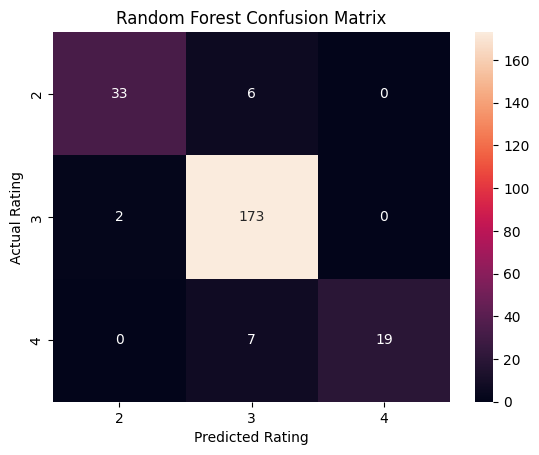

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=[2, 3, 4], yticklabels=[2, 3, 4])
plt.xlabel('Predicted Rating')
plt.ylabel('Actual Rating')
plt.title('Random Forest Confusion Matrix')
plt.show()

## Confirming the Result with Cross-Validation
We split the data into five parts, train on four and test on one, and repeat this five times. If the scores are similar every time, the model is stable.

In [11]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), X, y, cv=5)
print(scores)
print('Average accuracy:', scores.mean())

[0.89166667 0.95416667 0.9875     0.9        0.90833333]
Average accuracy: 0.9283333333333333


### Finding: Model Comparison
Random Forest gave the best results, with 93.8% accuracy on the test data and a recall of 0.85 for employees rated Good (2). Logistic Regression and Support Vector Machine reached only about 83% accuracy and found less than half of the employees rated Good. Random Forest is therefore chosen as the final model.

## Model for Hiring Decisions
A candidate does not yet have values such as salary hike, satisfaction scores or years since promotion. We therefore train a second Random Forest using only information known before an employee joins. Gender and marital status are left out so that hiring decisions are not based on personal characteristics.

In [12]:
hiring_features = ['Age', 'EducationBackground', 'EmpEducationLevel', 'EmpDepartment',
                   'EmpJobRole', 'EmpJobLevel', 'DistanceFromHome', 'NumCompaniesWorked',
                   'TotalWorkExperienceInYears', 'EmpHourlyRate',
                   'BusinessTravelFrequency', 'OverTime']

X_hire = encoded_data[hiring_features]

Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    X_hire, y, test_size=0.2, random_state=42, stratify=y)

hire_model = RandomForestClassifier(n_estimators=100, random_state=42)
hire_model.fit(Xh_train, yh_train)

hire_pred = hire_model.predict(Xh_test)
print('Hiring model accuracy:', accuracy_score(yh_test, hire_pred))
print(classification_report(yh_test, hire_pred))

Hiring model accuracy: 0.7125
              precision    recall  f1-score   support

           2       0.17      0.03      0.04        39
           3       0.73      0.97      0.83       175
           4       0.00      0.00      0.00        26

    accuracy                           0.71       240
   macro avg       0.30      0.33      0.29       240
weighted avg       0.56      0.71      0.61       240



In [13]:
hire_scores = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), X_hire, y, cv=5)
print(hire_scores)
print('Average accuracy:', hire_scores.mean())

[0.71666667 0.68333333 0.65833333 0.72083333 0.71666667]
Average accuracy: 0.6991666666666666


In [14]:
hire_model2 = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
hire_model2.fit(Xh_train, yh_train)

hire_pred2 = hire_model2.predict(Xh_test)
print('Accuracy:', accuracy_score(yh_test, hire_pred2))
print(classification_report(yh_test, hire_pred2))

Accuracy: 0.7041666666666667
              precision    recall  f1-score   support

           2       0.00      0.00      0.00        39
           3       0.73      0.97      0.83       175
           4       0.00      0.00      0.00        26

    accuracy                           0.70       240
   macro avg       0.24      0.32      0.28       240
weighted avg       0.53      0.70      0.60       240



/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### Finding: Model for Hiring Decisions
A model trained only on information available before joining (age, education, experience, job role and similar) reached about 70% accuracy, which is no better than always predicting the most common rating, Excellent (about 73%). It could not identify employees rated Good (2) or Outstanding (4), even after balancing the classes. This shows that a candidate's background does not reliably predict later performance in this data. The factors that matter most (salary hike, environment satisfaction and promotion wait) only exist after an employee joins. The full model (93% accuracy) is therefore recommended for analysing current employees, and hiring decisions should not rely on the hiring model alone.

## Saving the Models

In [15]:
import joblib

joblib.dump(rf_model, 'random_forest_model.pkl')
joblib.dump(list(X.columns), 'model_columns.pkl')
joblib.dump(hire_model, 'hiring_model.pkl')
joblib.dump(hiring_features, 'hiring_columns.pkl')

['hiring_columns.pkl']